In [ ]:
!wget https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
!unzip -q kagglecatsanddogs_5340.zip
!rm -rf PetImages/Cat/Thumbs.db PetImages/Dog/Thumbs.db
!pip install git+https://github.com/tensorflow/docs

--2026-07-03 17:12:12--  https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
Resolving download.microsoft.com (download.microsoft.com)... 23.193.226.61, 2600:1413:5000:12a1::317f, 2600:1413:5000:12ae::317f
Connecting to download.microsoft.com (download.microsoft.com)|23.193.226.61|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 824887076 (787M) [application/octet-stream]
Saving to: ‘kagglecatsanddogs_5340.zip’

kagglecatsanddogs_5 100%[===================>] 786.67M   203MB/s    in 4.3s    

2026-07-03 17:12:16 (184 MB/s) - ‘kagglecatsanddogs_5340.zip’ saved [824887076/824887076]

  Cloning https://github.com/tensorflow/docs to /tmp/pip-req-build-8y6kj4m8
  Running command git clone --filter=blob:none --quiet https://github.com/tensorflow/docs /tmp/pip-req-build-8y6kj4m8
  Resolved https://github.com/tensorflow/docs to commit 0054afff57cd4a4ea5389088a89942603461ee6f
  Preparing metadata (setup.py) ... do

In [ ]:
import os
num_skipped = 0
for folder_name in ("Cat", "Dog"):
    folder_path = os.path.join("PetImages", folder_name)
    for fname in os.listdir(folder_path):
        print(fname)
        fpath = os.path.join(folder_path, fname)
        try:
            fobj = open(fpath, "rb")
            is_jfif = b"JFIF" in fobj.peek(10)
        finally:
            fobj.close()

        if not is_jfif:
            num_skipped += 1
            os.remove(fpath)

print(f"Usunieto: {num_skipped}")

Strumieniowane dane wyjściowe obcięte do 5000 ostatnich wierszy.
2308.jpg
10550.jpg
4048.jpg
7877.jpg
11687.jpg
5061.jpg
10391.jpg
987.jpg
4923.jpg
1106.jpg
2784.jpg
8094.jpg
963.jpg
11111.jpg
9044.jpg
57.jpg
9328.jpg
257.jpg
4904.jpg
1337.jpg
4869.jpg
1111.jpg
304.jpg
1046.jpg
9171.jpg
2381.jpg
11718.jpg
11267.jpg
6960.jpg
1163.jpg
1364.jpg
1879.jpg
12495.jpg
7092.jpg
12381.jpg
4299.jpg
5229.jpg
5065.jpg
11023.jpg
11621.jpg
3151.jpg
7335.jpg
8274.jpg
10922.jpg
9682.jpg
6106.jpg
512.jpg
1936.jpg
10202.jpg
4709.jpg
6285.jpg
10693.jpg
1178.jpg
6190.jpg
2364.jpg
622.jpg
2097.jpg
6021.jpg
6954.jpg
11888.jpg
8006.jpg
4182.jpg
7052.jpg
12257.jpg
4508.jpg
1760.jpg
8525.jpg
3890.jpg
9921.jpg
4654.jpg
2437.jpg
9051.jpg
11407.jpg
11836.jpg
5775.jpg
2275.jpg
9561.jpg
3371.jpg
4342.jpg
4124.jpg
764.jpg
4620.jpg
2536.jpg
3332.jpg
4857.jpg
2652.jpg
3557.jpg
7498.jpg
10575.jpg
2727.jpg
8878.jpg
11060.jpg
4296.jpg
8276.jpg
3418.jpg
2465.jpg
3254.jpg
2220.jpg
4030.jpg
12143.jpg
11978.jpg
3299.jpg
2762.

In [ ]:
import keras
import keras.callbacks
import keras.utils
import matplotlib.pyplot as plt
import numpy as np
from keras import layers
from tensorflow import data as tf_data
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers

batch_size = 128
image_size = (100, 100)

train_ds, val_ds = keras.utils.image_dataset_from_directory(
    "PetImages",
    validation_split=0.2,
    subset="both",
    seed=1337,
    image_size = image_size,
    batch_size = batch_size
)

train_ds = train_ds.cache().prefetch(tf_data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf_data.AUTOTUNE)

Found 23410 files belonging to 2 classes.
Using 18728 files for training.
Using 4682 files for validation.


In [ ]:
def make_model_small_cnn_flatten(input_shape=(100, 100, 3)):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)

    x = layers.Conv2D(16, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.Flatten()(x)

    outputs = layers.Dense(1, activation=None)(x)

    return keras.Model(inputs, outputs)
model_small_cnn_flatten = make_model_small_cnn_flatten(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_small_cnn_flatten.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_residual = model_small_cnn_flatten.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)



Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.5802 - loss: 0.6463 - pure_loss: 0.6464 - val_accuracy: 0.5767 - val_loss: 0.6178 - val_pure_loss: 0.6173
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6974 - loss: 0.5568 - pure_loss: 0.5570 - val_accuracy: 0.6630 - val_loss: 0.5464 - val_pure_loss: 0.5460
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7348 - loss: 0.5082 - pure_loss: 0.5083 - val_accuracy: 0.7063 - val_loss: 0.4988 - val_pure_loss: 0.4984
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7668 - loss: 0.4648 - pure_loss: 0.4646 - val_accuracy: 0.7296 - val_loss: 0.4732 - val_pure_loss: 0.4729
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7860 - loss: 0.4322 - pure_loss: 0.4317 - val_accuracy: 0.7486 - val_loss: 0.4510 - val_pure_loss: 0.4509
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8013 - loss: 0.4052 - pure_loss: 0.4047 - val_accuracy: 0.7655 - va

In [ ]:
!pip install git+https://github.com/tensorflow/docs

  Cloning https://github.com/tensorflow/docs to /tmp/pip-req-build-pe2k54id
  Running command git clone --filter=blob:none --quiet https://github.com/tensorflow/docs /tmp/pip-req-build-pe2k54id
  Resolved https://github.com/tensorflow/docs to commit 0054afff57cd4a4ea5389088a89942603461ee6f
  Preparing metadata (setup.py) ... done


In [ ]:
import itertools
import matplotlib.pyplot as plt
import pandas as pd

# Słownik na historie treningowe
histories_cnn_flatten = {}

# Definiujemy dostępne warianty technik regularyzacyjnych
reg_options = {
    "none": None,
    "l1": keras.regularizers.l1(0.0001),
    "l2": keras.regularizers.l2(0.0001),
    "l1_l2": keras.regularizers.l1_l2(l1=0.0001, l2=0.0001),
}

drop_options = {"none": 0.0, "drop_02": 0.2, "drop_05": 0.5}

bn_options = {"none": False, "bn": True}

# Generujemy 24 kombinacje
combinations = list(
    itertools.product(reg_options.items(), drop_options.items(), bn_options.items())
)

GLOBAL_SEED = 1337
print(
    f"Rozpoczynanie eksperymentu dla {len(combinations)} kombinacji modeli Small CNN Flatten..."
)

for (reg_name, reg_val), (drop_name, drop_val), (bn_name, bn_val) in combinations:

    # Czyszczenie sesji i ustawianie powtarzalnego seedu
    keras.backend.clear_session()
    tf.random.set_seed(GLOBAL_SEED)

    # Budowanie unikalnej nazwy klucza dla historii
    suffix_parts = []
    if reg_name != "none":
        suffix_parts.append(reg_name)
    if drop_name != "none":
        suffix_parts.append(drop_name)
    if bn_name != "none":
        suffix_parts.append(bn_name)

    suffix = "_" + "_".join(suffix_parts) if suffix_parts else ""
    history_key = f"small_cnn_flatten{suffix}"
    model_name = f"model_{history_key}"

    # DYNAMICZNA BUDOWA ARCHITEKTURY SMALL CNN FLATTEN
    inputs = keras.Input(shape=(100, 100, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)

    # Blok 1
    x = layers.Conv2D(
        16, 3, strides=2, padding="same", kernel_regularizer=reg_val, use_bias=not bn_val
    )(x)
    if bn_val:
        x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if drop_val > 0.0:
        x = layers.Dropout(drop_val)(x)
    x = layers.MaxPooling2D(2)(x)

    # Blok 2
    x = layers.Conv2D(
        32, 3, padding="same", kernel_regularizer=reg_val, use_bias=not bn_val
    )(x)
    if bn_val:
        x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if drop_val > 0.0:
        x = layers.Dropout(drop_val)(x)
    x = layers.MaxPooling2D(2)(x)

    # Blok 3
    x = layers.Conv2D(
        64, 3, padding="same", kernel_regularizer=reg_val, use_bias=not bn_val
    )(x)
    if bn_val:
        x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if drop_val > 0.0:
        x = layers.Dropout(drop_val)(x)

    # Końcówka modelu (Wersja z Flatten)
    x = layers.Flatten()(x)
    outputs = layers.Dense(1, activation=None)(x)

    model = keras.Model(inputs, outputs, name=model_name)

    patience_val = 10
    callbacks = [
        EarlyStopping(
            monitor="val_pure_loss",
            patience=patience_val,
            restore_best_weights=True,
            verbose=0,
        )
    ]

    # Kompilacja zgodnie z Twoimi parametrami (z binary crossentropy z logitów)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.BinaryCrossentropy(from_logits=True),
        metrics=[
            "accuracy",
            keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True),
        ],
    )

    print(f"Trenowanie: {model_name} (patience={patience_val})...")

    # Trening na pobranych wcześniej i przygotowanych zbiorach train_ds oraz val_ds
    history = model.fit(
        train_ds,
        epochs=150,  # Zgodnie z Twoim zleceniem: maks 150 epok
        validation_data=val_ds,
        callbacks=callbacks,
        verbose=0,  # Wyłączone logi epok, aby nie zaśmiecać konsoli
    )

    # Zapisanie do słownika zbiorczego
    histories_cnn_flatten[history_key] = history

Rozpoczynanie eksperymentu dla 24 kombinacji modeli Small CNN Flatten...
Trenowanie: model_small_cnn_flatten (patience=10)...
Trenowanie: model_small_cnn_flatten_bn (patience=10)...
Trenowanie: model_small_cnn_flatten_drop_02 (patience=10)...
Trenowanie: model_small_cnn_flatten_drop_02_bn (patience=10)...
Trenowanie: model_small_cnn_flatten_drop_05 (patience=10)...
Trenowanie: model_small_cnn_flatten_drop_05_bn (patience=10)...
Trenowanie: model_small_cnn_flatten_l1 (patience=10)...
Trenowanie: model_small_cnn_flatten_l1_bn (patience=10)...
Trenowanie: model_small_cnn_flatten_l1_drop_02 (patience=10)...
Trenowanie: model_small_cnn_flatten_l1_drop_02_bn (patience=10)...
Trenowanie: model_small_cnn_flatten_l1_drop_05 (patience=10)...
Trenowanie: model_small_cnn_flatten_l1_drop_05_bn (patience=10)...
Trenowanie: model_small_cnn_flatten_l2 (patience=10)...
Trenowanie: model_small_cnn_flatten_l2_bn (patience=10)...
Trenowanie: model_small_cnn_flatten_l2_drop_02 (patience=10)...
Trenowanie: 

In [ ]:
results_data = []

for key, history in histories_cnn_flatten.items():
    # Pobieramy indeks najlepszej epoki na podstawie najniższego błędu walidacji
    val_pure_loss_history = history.history["val_pure_loss"]
    best_epoch_idx = val_pure_loss_history.index(min(val_pure_loss_history))

    results_data.append(
        {
            "Model Wariant": key,
            "Liczba epok": len(val_pure_loss_history),
            "Best Epoch": best_epoch_idx + 1,
            "Train Loss": history.history["pure_loss"][best_epoch_idx],
            "Val Loss": history.history["val_pure_loss"][best_epoch_idx],
            "Train Acc": history.history["accuracy"][best_epoch_idx],
            "Val Acc": history.history["val_accuracy"][best_epoch_idx],
        }
    )

# Konwersja na DataFrame i wyświetlenie
df_results = pd.DataFrame(results_data)
# Sortowanie od najlepszego wyniku na zbiorze walidacyjnym (najwyższy Accuracy)
df_results = df_results.sort_values(by="Val Acc", ascending=False).reset_index(
    drop=True
)

# Wyświetlenie pełnej tabeli w środowisku (np. Jupyter / Colab)
print("\n--- ZESTAWIENIE WYNIKÓW DLA 24 WARIANTÓW ---")
display(df_results)


--- ZESTAWIENIE WYNIKÓW DLA 24 WARIANTÓW ---


,Model Wariant,Liczba epok,Best Epoch,Train Loss,Val Loss,Train Acc,Val Acc
0,small_cnn_flatten_drop_05,75,65,0.263174,0.346772,0.883116,0.850705
1,small_cnn_flatten_l1_l2_drop_02,47,37,0.261347,0.346359,0.881247,0.844511
2,small_cnn_flatten_l2_drop_05,65,55,0.293020,0.344039,0.868593,0.837463
3,small_cnn_flatten_l1_drop_02,60,50,0.221558,0.349953,0.901217,0.833832
4,small_cnn_flatten_drop_02,37,27,0.244450,0.353072,0.891927,0.833618
5,small_cnn_flatten_l2_drop_02,32,22,0.267307,0.364146,0.878738,0.831055
6,small_cnn_flatten_l2,26,16,0.287608,0.379134,0.870034,0.822085
7,small_cnn_flatten_drop_02_bn,25,15,0.272769,0.387931,0.877029,0.818667
8,small_cnn_flatten,23,13,0.286782,0.395352,0.870782,0.813541
9,small_cnn_flatten_l1_drop_05,85,75,0.323676,0.387284,0.849263,0.803076


In [ ]:
def make_model_small_cnn_gap(input_shape=(100, 100, 3)):
    inputs = keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)

    x = layers.Conv2D(16, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)

    outputs = layers.Dense(1, activation=None)(x)

    return keras.Model(inputs, outputs)
model_small_cnn_gap = make_model_small_cnn_gap(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_small_cnn_gap.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_residual = model_small_cnn_gap.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)

Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.5558 - loss: 0.6645 - pure_loss: 0.6645 - val_accuracy: 0.5861 - val_loss: 0.6376 - val_pure_loss: 0.6373
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5992 - loss: 0.6389 - pure_loss: 0.6390 - val_accuracy: 0.5940 - val_loss: 0.6272 - val_pure_loss: 0.6269
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6089 - loss: 0.6291 - pure_loss: 0.6291 - val_accuracy: 0.5925 - val_loss: 0.6186 - val_pure_loss: 0.6185
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6291 - loss: 0.6151 - pure_loss: 0.6151 - val_accuracy: 0.6207 - val_loss: 0.5985 - val_pure_loss: 0.5984
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6446 - loss: 0.6015 - pure_loss: 0.6015 - val_accuracy: 0.6318 - val_loss: 0.5870 - val_pure_loss: 0.5869
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6591 - loss: 0.5883 - pure_loss: 0.5882 - val_accuracy: 0.6175 - va

In [ ]:
# Słownik na historie treningowe wersji GAP
histories_cnn_gap = {}

# Definiujemy dostępne warianty technik regularyzacyjnych
reg_options = {
    "none": None,
    "l1": keras.regularizers.l1(0.0001),
    "l2": keras.regularizers.l2(0.0001),
    "l1_l2": keras.regularizers.l1_l2(l1=0.0001, l2=0.0001),
}

drop_options = {"none": 0.0, "drop_02": 0.2, "drop_05": 0.5}

bn_options = {"none": False, "bn": True}

# Generujemy 24 kombinacje
combinations = list(
    itertools.product(reg_options.items(), drop_options.items(), bn_options.items())
)

GLOBAL_SEED = 1337
print(
    f"Rozpoczynanie eksperymentu dla {len(combinations)} kombinacji modeli Small CNN GAP..."
)

for (reg_name, reg_val), (drop_name, drop_val), (bn_name, bn_val) in combinations:

    # Czyszczenie sesji i ustawianie powtarzalnego seedu
    keras.backend.clear_session()
    tf.random.set_seed(GLOBAL_SEED)

    # Budowanie unikalnej nazwy klucza dla historii
    suffix_parts = []
    if reg_name != "none":
        suffix_parts.append(reg_name)
    if drop_name != "none":
        suffix_parts.append(drop_name)
    if bn_name != "none":
        suffix_parts.append(bn_name)

    suffix = "_" + "_".join(suffix_parts) if suffix_parts else ""
    history_key = f"small_cnn_gap{suffix}"
    model_name = f"model_{history_key}"

    # DYNAMICZNA BUDOWA ARCHITEKTURY SMALL CNN GAP
    inputs = keras.Input(shape=(100, 100, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)

    # Blok 1
    x = layers.Conv2D(
        16, 3, strides=2, padding="same", kernel_regularizer=reg_val, use_bias=not bn_val
    )(x)
    if bn_val:
        x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if drop_val > 0.0:
        x = layers.Dropout(drop_val)(x)
    x = layers.MaxPooling2D(2)(x)

    # Blok 2
    x = layers.Conv2D(
        32, 3, padding="same", kernel_regularizer=reg_val, use_bias=not bn_val
    )(x)
    if bn_val:
        x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if drop_val > 0.0:
        x = layers.Dropout(drop_val)(x)
    x = layers.MaxPooling2D(2)(x)

    # Blok 3
    x = layers.Conv2D(
        64, 3, padding="same", kernel_regularizer=reg_val, use_bias=not bn_val
    )(x)
    if bn_val:
        x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if drop_val > 0.0:
        x = layers.Dropout(drop_val)(x)

    # --- ZMIANA: Global Average Pooling zamiast Flatten ---
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation=None)(x)

    model = keras.Model(inputs, outputs, name=model_name)

    # Dobór patience: dla drop_02 wynosi 5, dla pozostałych 10
    patience_val = 10
    callbacks = [
        EarlyStopping(
            monitor="val_pure_loss",
            patience=patience_val,
            restore_best_weights=True,
            verbose=0,
        )
    ]

    # Kompilacja (identyczna jak dla wersji Flatten)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.BinaryCrossentropy(from_logits=True),
        metrics=[
            "accuracy",
            keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True),
        ],
    )

    print(f"Trenowanie: {model_name} (patience={patience_val})...")

    # Trening na tych samych zbiorach danych
    history = model.fit(
        train_ds,
        epochs=150,
        validation_data=val_ds,
        callbacks=callbacks,
        verbose=0,
    )

    # Zapisanie do nowego słownika zbiorczego
    histories_cnn_gap[history_key] = history

Rozpoczynanie eksperymentu dla 24 kombinacji modeli Small CNN GAP...
Trenowanie: model_small_cnn_gap (patience=10)...
Trenowanie: model_small_cnn_gap_bn (patience=10)...
Trenowanie: model_small_cnn_gap_drop_02 (patience=10)...
Trenowanie: model_small_cnn_gap_drop_02_bn (patience=10)...
Trenowanie: model_small_cnn_gap_drop_05 (patience=10)...
Trenowanie: model_small_cnn_gap_drop_05_bn (patience=10)...
Trenowanie: model_small_cnn_gap_l1 (patience=10)...
Trenowanie: model_small_cnn_gap_l1_bn (patience=10)...
Trenowanie: model_small_cnn_gap_l1_drop_02 (patience=10)...
Trenowanie: model_small_cnn_gap_l1_drop_02_bn (patience=10)...
Trenowanie: model_small_cnn_gap_l1_drop_05 (patience=10)...
Trenowanie: model_small_cnn_gap_l1_drop_05_bn (patience=10)...
Trenowanie: model_small_cnn_gap_l2 (patience=10)...
Trenowanie: model_small_cnn_gap_l2_bn (patience=10)...
Trenowanie: model_small_cnn_gap_l2_drop_02 (patience=10)...
Trenowanie: model_small_cnn_gap_l2_drop_02_bn (patience=10)...
Trenowanie: m

In [ ]:
results_gap_data = []

for key, history in histories_cnn_gap.items():
    val_pure_loss_history = history.history["val_pure_loss"]
    best_epoch_idx = val_pure_loss_history.index(min(val_pure_loss_history))

    results_gap_data.append(
        {
            "Model Wariant (GAP)": key,
            "Liczba epok": len(val_pure_loss_history),
            "Best Epoch": best_epoch_idx + 1,
            "Train Loss": history.history["pure_loss"][best_epoch_idx],
            "Val Loss": history.history["val_pure_loss"][best_epoch_idx],
            "Train Acc": history.history["accuracy"][best_epoch_idx],
            "Val Acc": history.history["val_accuracy"][best_epoch_idx],
        }
    )

df_gap_results = pd.DataFrame(results_gap_data)
df_gap_results = df_gap_results.sort_values(by="Val Acc", ascending=False).reset_index(
    drop=True
)

print("\n--- ZESTAWIENIE WYNIKÓW DLA 24 WARIANTÓW (SMALL CNN GAP) ---")
display(df_gap_results)


--- ZESTAWIENIE WYNIKÓW DLA 24 WARIANTÓW (SMALL CNN GAP) ---


,Model Wariant (GAP),Liczba epok,Best Epoch,Train Loss,Val Loss,Train Acc,Val Acc
0,small_cnn_gap_l1_drop_02_bn,83,73,0.269850,0.328302,0.877029,0.850918
1,small_cnn_gap_drop_02,112,102,0.316472,0.351990,0.856098,0.838744
2,small_cnn_gap_l2_drop_02_bn,54,44,0.311881,0.364141,0.857379,0.829560
3,small_cnn_gap_l2,135,125,0.301029,0.369985,0.864107,0.822725
4,small_cnn_gap_l2_drop_02,150,150,0.329072,0.363599,0.846487,0.818026
5,small_cnn_gap_l2_bn,24,14,0.376230,0.399483,0.821604,0.816745
6,small_cnn_gap_l1_bn,27,17,0.368049,0.401751,0.826516,0.816318
7,small_cnn_gap_l1_l2_bn,23,13,0.391600,0.430754,0.811299,0.796668
8,small_cnn_gap_l1_l2_drop_02_bn,24,14,0.414003,0.436480,0.796882,0.795814
9,small_cnn_gap,91,81,0.353111,0.409526,0.834739,0.795387


In [ ]:
def make_model_big_cnn_flatten(input_shape=(100, 100, 3)):
    model_layers = [
        layers.Input(shape=input_shape),
        layers.Rescaling(1.0 / 255)
    ]

    model_layers.append(layers.Conv2D(16, 3, strides=2, padding="same"))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Conv2D(32, 3, padding="same"))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Conv2D(64, 3, padding="same"))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Flatten())
    model_layers.append(layers.Dense(512))
    model_layers.append(layers.Activation("relu"))

    model_layers.append(layers.Dense(1, activation=None))

    return keras.Sequential(model_layers, name="model_vgg_base")

model_big_cnn_flatten = make_model_big_cnn_flatten(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_big_cnn_flatten.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_big_cnn_flatten = model_big_cnn_flatten.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)


Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.5929 - loss: 0.6369 - pure_loss: 0.6369 - val_accuracy: 0.6354 - val_loss: 0.5776 - val_pure_loss: 0.5766
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7110 - loss: 0.5360 - pure_loss: 0.5357 - val_accuracy: 0.7108 - val_loss: 0.5041 - val_pure_loss: 0.5031
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7535 - loss: 0.4761 - pure_loss: 0.4758 - val_accuracy: 0.7065 - val_loss: 0.4919 - val_pure_loss: 0.4910
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7879 - loss: 0.4262 - pure_loss: 0.4257 - val_accuracy: 0.7144 - val_loss: 0.4910 - val_pure_loss: 0.4900
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8114 - loss: 0.3889 - pure_loss: 0.3882 - val_accuracy: 0.7830 - val_loss: 0.4236 - val_pure_loss: 0.4226
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8327 - loss: 0.3542 - pure_loss: 0.3536 - val_accuracy: 0.8014 - va

In [ ]:
# Słownik na historie treningowe wersji Big CNN Flatten
histories_big_flatten = {}

# Definiujemy dostępne warianty technik regularyzacyjnych
reg_options = {
    "none": None,
    "l1": regularizers.l1(0.0001),
    "l2": regularizers.l2(0.001),
    "l1_l2": regularizers.l1_l2(l1=0.0001, l2=0.001),
}

drop_options = {"none": 0.0, "drop_02": 0.2, "drop_05": 0.5}

bn_options = {"none": False, "bn": True}

# Generujemy 24 kombinacje
combinations = list(
    itertools.product(reg_options.items(), drop_options.items(), bn_options.items())
)

GLOBAL_SEED = 1337
epochs = 150

print(
    f"Rozpoczynanie eksperymentu dla {len(combinations)} kombinacji modelu Big CNN Flatten..."
)

for (reg_name, reg_val), (drop_name, drop_val), (bn_name, bn_val) in combinations:

    # Czyszczenie sesji i ustawianie powtarzalnego seedu
    keras.backend.clear_session()
    tf.random.set_seed(GLOBAL_SEED)

    # Budowanie unikalnej nazwy klucza dla historii
    suffix_parts = []
    if reg_name != "none":
        suffix_parts.append(reg_name)
    if drop_name != "none":
        suffix_parts.append(drop_name)
    if bn_name != "none":
        suffix_parts.append(bn_name)

    suffix = "_" + "_".join(suffix_parts) if suffix_parts else ""
    history_key = f"big_flatten{suffix}"
    model_name = f"model_big_flatten{suffix}"

    # DYNAMICZNA BUDOWA ARCHITEKTURY BIG CNN FLATTEN
    model_layers = [
        layers.Input(shape=(100, 100, 3)),
        layers.Rescaling(1.0 / 255),
    ]

    # Blok 1
    model_layers.append(
        layers.Conv2D(
            16,
            3,
            strides=2,
            padding="same",
            kernel_regularizer=reg_val,
            use_bias=not bn_val,
        )
    )
    if bn_val:
        model_layers.append(layers.BatchNormalization())
    model_layers.append(layers.Activation("relu"))
    if drop_val > 0.0:
        model_layers.append(layers.Dropout(drop_val, seed=GLOBAL_SEED))
    model_layers.append(layers.MaxPooling2D(2))

    # Blok 2
    model_layers.append(
        layers.Conv2D(
            32, 3, padding="same", kernel_regularizer=reg_val, use_bias=not bn_val
        )
    )
    if bn_val:
        model_layers.append(layers.BatchNormalization())
    model_layers.append(layers.Activation("relu"))
    if drop_val > 0.0:
        model_layers.append(layers.Dropout(drop_val, seed=GLOBAL_SEED))
    model_layers.append(layers.MaxPooling2D(2))

    # Blok 3
    model_layers.append(
        layers.Conv2D(
            64, 3, padding="same", kernel_regularizer=reg_val, use_bias=not bn_val
        )
    )
    if bn_val:
        model_layers.append(layers.BatchNormalization())
    model_layers.append(layers.Activation("relu"))
    if drop_val > 0.0:
        model_layers.append(layers.Dropout(drop_val, seed=GLOBAL_SEED))
    model_layers.append(layers.MaxPooling2D(2))

    # Ciężki klasyfikator gęsty z warstwą Flatten
    model_layers.append(layers.Flatten())

    # Potężna warstwa ukryta (512 neuronów)
    model_layers.append(
        layers.Dense(512, kernel_regularizer=reg_val, use_bias=not bn_val)
    )
    if bn_val:
        model_layers.append(layers.BatchNormalization())
    model_layers.append(layers.Activation("relu"))
    if drop_val > 0.0:
        model_layers.append(layers.Dropout(drop_val, seed=GLOBAL_SEED))

    # Warstwa wyjściowa
    model_layers.append(layers.Dense(1, activation=None))

    model = keras.Sequential(model_layers, name=model_name)

    callbacks = [
        EarlyStopping(
            monitor="val_pure_loss",
            patience=10,
            restore_best_weights=True,
            verbose=0,
        )
    ]

    # Kompilacja ze standardowym uczeniem 0.001
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.BinaryCrossentropy(from_logits=True),
        metrics=[
            "accuracy",
            keras.losses.BinaryCrossentropy(from_logits=True, name="pure_loss"),
        ],
    )

    print(f" -> Trenowanie: {model_name}...")

    # Trening na Twoich potokach danych
    history = model.fit(
        train_ds,
        epochs=epochs,
        validation_data=val_ds,
        callbacks=callbacks,
        verbose=0,
    )

    # Zapisanie do dedykowanego słownika zbiorczego
    histories_big_flatten[history_key] = history

Rozpoczynanie eksperymentu dla 24 kombinacji modelu Big CNN Flatten...
 -> Trenowanie: model_big_flatten...
 -> Trenowanie: model_big_flatten_bn...
 -> Trenowanie: model_big_flatten_drop_02...
 -> Trenowanie: model_big_flatten_drop_02_bn...
 -> Trenowanie: model_big_flatten_drop_05...
 -> Trenowanie: model_big_flatten_drop_05_bn...
 -> Trenowanie: model_big_flatten_l1...
 -> Trenowanie: model_big_flatten_l1_bn...
 -> Trenowanie: model_big_flatten_l1_drop_02...
 -> Trenowanie: model_big_flatten_l1_drop_02_bn...
 -> Trenowanie: model_big_flatten_l1_drop_05...
 -> Trenowanie: model_big_flatten_l1_drop_05_bn...
 -> Trenowanie: model_big_flatten_l2...
 -> Trenowanie: model_big_flatten_l2_bn...
 -> Trenowanie: model_big_flatten_l2_drop_02...
 -> Trenowanie: model_big_flatten_l2_drop_02_bn...
 -> Trenowanie: model_big_flatten_l2_drop_05...
 -> Trenowanie: model_big_flatten_l2_drop_05_bn...
 -> Trenowanie: model_big_flatten_l1_l2...
 -> Trenowanie: model_big_flatten_l1_l2_bn...
 -> Trenowanie:

In [ ]:
results_big_flatten_data = []

for key, history in histories_big_flatten.items():
    val_pure_loss_history = history.history["val_pure_loss"]
    best_epoch_idx = np.argmin(val_pure_loss_history)

    # Wyciągamy informacje o konfiguracji na podstawie nazwy klucza
    parts = key.split("_")
    reg_type = parts[2] if "big_flatten" in key and len(parts) > 2 else "none"

    results_big_flatten_data.append(
        {
            "Model Key": key,
            "Liczba epok": len(val_pure_loss_history),
            "Best Epoch": best_epoch_idx + 1,
            "Train Accuracy": history.history["accuracy"][best_epoch_idx],
            "Val Accuracy": history.history["val_accuracy"][best_epoch_idx],
            "Train Pure Loss": history.history["pure_loss"][best_epoch_idx],
            "Val Pure Loss": history.history["val_pure_loss"][best_epoch_idx],
        }
    )

df_big_flatten_results = pd.DataFrame(results_big_flatten_data)
df_big_flatten_results = df_big_flatten_results.sort_values(
    by="Val Accuracy", ascending=False
).reset_index(drop=True)

print(
    "\n"
    + "=" * 60
    + "\nKOŃCOWA TABELA WYNIKÓW (Big CNN Flatten - 24 Warianty):\n"
    + "=" * 60
)
print(df_big_flatten_results.to_string(index=False))

# Zapis do pliku CSV na wypadek konieczności użycia w Excelu lub Wordzie
df_big_flatten_results.to_csv("big_flatten_grid_search_results.csv", index=False)


KOŃCOWA TABELA WYNIKÓW (Big CNN Flatten - 24 Warianty):
                   Model Key  Liczba epok  Best Epoch  Train Accuracy  Val Accuracy  Train Pure Loss  Val Pure Loss
      big_flatten_l2_drop_02           50          40        0.882742      0.857967         0.260322       0.312106
           big_flatten_l1_l2           50          40        0.865602      0.836608         0.297391       0.378138
              big_flatten_l2           28          18        0.880073      0.836395         0.267516       0.353367
big_flatten_l1_l2_drop_02_bn           37          27        0.911897      0.833618         0.204018       0.328348
         big_flatten_drop_05           67          57        0.944255      0.831909         0.134986       0.373873
   big_flatten_l2_drop_02_bn           38          28        0.931707      0.827424         0.156453       0.364816
   big_flatten_l1_drop_02_bn           27          17        0.886801      0.825715         0.252134       0.365132
              b

In [ ]:
def make_model_residual(input_shape=(100, 100, 3), l2_val=0.0001):
    inputs = keras.Input(shape=input_shape)
    x = inputs
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x

    for size in [128, 256, 512]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(size, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation=None)(x)

    return keras.Model(inputs, outputs)

model_residual = make_model_residual(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_residual.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_residual = model_residual.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)


In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [ ]:
def make_model_big_cnn_flatten_aug(input_shape=(100, 100, 3)):
    model_layers = [
        layers.Input(shape=input_shape),
        data_augmentation,
        layers.Rescaling(1.0 / 255)
    ]

    model_layers.append(layers.Conv2D(16, 3, strides=2, padding="same"))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Conv2D(32, 3, padding="same"))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Conv2D(64, 3, padding="same"))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Flatten())
    model_layers.append(layers.Dense(512))
    model_layers.append(layers.Activation("relu"))

    model_layers.append(layers.Dense(1, activation=None))

    return keras.Sequential(model_layers)

model_big_cnn_flatten_aug = make_model_big_cnn_flatten_aug(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_big_cnn_flatten_aug.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_big_cnn_flatten_aug = model_big_cnn_flatten_aug.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)

Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.5534 - loss: 0.6607 - pure_loss: 0.6604 - val_accuracy: 0.6634 - val_loss: 0.5857 - val_pure_loss: 0.5850
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6716 - loss: 0.5796 - pure_loss: 0.5796 - val_accuracy: 0.7313 - val_loss: 0.5271 - val_pure_loss: 0.5264
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7103 - loss: 0.5354 - pure_loss: 0.5350 - val_accuracy: 0.7454 - val_loss: 0.4950 - val_pure_loss: 0.4949
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7304 - loss: 0.5082 - pure_loss: 0.5075 - val_accuracy: 0.7666 - val_loss: 0.4757 - val_pure_loss: 0.4758
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7495 - loss: 0.4848 - pure_loss: 0.4842 - val_accuracy: 0.7751 - val_loss: 0.4627 - val_pure_loss: 0.4631
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7614 - loss: 0.4644 - pure_loss: 0.4637 - val_accuracy: 0.7619 - v

In [ ]:
def make_model_big_flatten_regularized_aug(input_shape=(100, 100, 3)):
    reg_val = regularizers.l2(0.001)

    model_layers = [
        layers.Input(shape=input_shape),
        data_augmentation,
        layers.Rescaling(1.0 / 255)
    ]

    model_layers.append(layers.Conv2D(16, 3, strides=2, padding="same", kernel_regularizer=reg_val))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.Dropout(0.2))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Conv2D(32, 3, padding="same", kernel_regularizer=reg_val))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.Dropout(0.2))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Conv2D(64, 3, padding="same", kernel_regularizer=reg_val))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.Dropout(0.2))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Flatten())
    model_layers.append(layers.Dense(512, kernel_regularizer=reg_val))
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.Dropout(0.2))

    model_layers.append(layers.Dense(1, activation=None))

    return keras.Sequential(model_layers)

model_big_flatten_regularized_aug = make_model_big_flatten_regularized_aug(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_big_flatten_regularized_aug.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_big_flatten_regularized_aug = model_big_flatten_regularized_aug.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)

Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.5492 - loss: 0.9643 - pure_loss: 0.6734 - val_accuracy: 0.5972 - val_loss: 0.7402 - val_pure_loss: 0.6118
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6556 - loss: 0.6906 - pure_loss: 0.5984 - val_accuracy: 0.6480 - val_loss: 0.6468 - val_pure_loss: 0.5790
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6800 - loss: 0.6247 - pure_loss: 0.5674 - val_accuracy: 0.6717 - val_loss: 0.6015 - val_pure_loss: 0.5505
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7101 - loss: 0.5874 - pure_loss: 0.5393 - val_accuracy: 0.6901 - val_loss: 0.5735 - val_pure_loss: 0.5269
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7219 - loss: 0.5681 - pure_loss: 0.5221 - val_accuracy: 0.6672 - val_loss: 0.5733 - val_pure_loss: 0.5281
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7304 - loss: 0.5554 - pure_loss: 0.5104 - val_accuracy: 0.7211 - va

In [ ]:
def make_model_big_flatten_regularized_aug_bn(input_shape=(100, 100, 3)):
    reg_val = regularizers.l2(0.001)

    model_layers = [
        layers.Input(shape=input_shape),
        data_augmentation,
        layers.Rescaling(1.0 / 255)
    ]

    model_layers.append(layers.Conv2D(16, 3, strides=2, padding="same", kernel_regularizer=reg_val))
    model_layers.append(layers.BatchNormalization())
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.Dropout(0.2))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Conv2D(32, 3, padding="same", kernel_regularizer=reg_val))
    model_layers.append(layers.BatchNormalization())
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.Dropout(0.2))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Conv2D(64, 3, padding="same", kernel_regularizer=reg_val))
    model_layers.append(layers.BatchNormalization())
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.Dropout(0.2))
    model_layers.append(layers.MaxPooling2D(2))

    model_layers.append(layers.Flatten())
    model_layers.append(layers.Dense(512, kernel_regularizer=reg_val))
    model_layers.append(layers.BatchNormalization())
    model_layers.append(layers.Activation("relu"))
    model_layers.append(layers.Dropout(0.2))

    model_layers.append(layers.Dense(1, activation=None))

    return keras.Sequential(model_layers)

model_big_flatten_regularized_aug_bn = make_model_big_flatten_regularized_aug_bn(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_big_flatten_regularized_aug_bn.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_big_flatten_regularized_aug_bn = model_big_flatten_regularized_aug_bn.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)

Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.6709 - loss: 1.3075 - pure_loss: 0.6211 - val_accuracy: 0.4957 - val_loss: 1.3083 - val_pure_loss: 0.8186
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7262 - loss: 0.9042 - pure_loss: 0.5266 - val_accuracy: 0.5062 - val_loss: 0.9640 - val_pure_loss: 0.6761
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7502 - loss: 0.7260 - pure_loss: 0.4901 - val_accuracy: 0.5976 - val_loss: 0.7807 - val_pure_loss: 0.5889
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7634 - loss: 0.6371 - pure_loss: 0.4694 - val_accuracy: 0.6914 - val_loss: 0.6686 - val_pure_loss: 0.5226
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7746 - loss: 0.5864 - pure_loss: 0.4522 - val_accuracy: 0.7072 - val_loss: 0.6711 - val_pure_loss: 0.5477
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7832 - loss: 0.5591 - pure_loss: 0.4399 - val_accuracy: 0.7742

In [ ]:
def make_model_residual(input_shape=(100, 100, 3), l2_val=0.00001):
    # l2_reg = regularizers.l2(l2_val)

    inputs = keras.Input(shape=input_shape)
    x = inputs
    # x = data_augmentation(x)
    x = layers.Rescaling(1.0 / 255)(x)
    # x = layers.Conv2D(128, 3, strides=2, padding="same", kernel_regularizer=l2_reg)(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    # x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x

    for size in [128, 256, 512]:
        x = layers.Activation("relu")(x)
        # x = layers.SeparableConv2D(size, 3, padding="same", pointwise_regularizer=l2_reg)(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        # x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        # x = layers.SeparableConv2D(size, 3, padding="same", pointwise_regularizer=l2_reg)(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        # x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        # residual = layers.Conv2D(size, 1, strides=2, padding="same", kernel_regularizer=l2_reg)(previous_block_activation)
        residual = layers.Conv2D(size, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    # x = layers.SeparableConv2D(1024, 3, padding="same", pointwise_regularizer=l2_reg)(x)
    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    # x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    # x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation=None)(x)

    return keras.Model(inputs, outputs)

model_residual = make_model_residual(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_residual.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_residual = model_residual.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)


Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 23s 92ms/step - accuracy: 0.5043 - loss: 0.6862 - pure_loss: 0.6863 - val_accuracy: 0.4957 - val_loss: 0.6739 - val_pure_loss: 0.6740
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.5246 - loss: 0.6723 - pure_loss: 0.6724 - val_accuracy: 0.5021 - val_loss: 0.6656 - val_pure_loss: 0.6657
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.5729 - loss: 0.6511 - pure_loss: 0.6510 - val_accuracy: 0.5461 - val_loss: 0.6446 - val_pure_loss: 0.6446
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6368 - loss: 0.6146 - pure_loss: 0.6145 - val_accuracy: 0.5974 - val_loss: 0.6153 - val_pure_loss: 0.6154
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6664 - loss: 0.5840 - pure_loss: 0.5838 - val_accuracy: 0.6367 - val_loss: 0.5713 - val_pure_loss: 0.5716
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.7062 - loss: 0.5471 - pure_loss: 0.5470 - val_accuracy: 0.715

In [ ]:
def make_model_residual_drop_02(input_shape=(100, 100, 3)):

    inputs = keras.Input(shape=input_shape)
    x = inputs
    # x = data_augmentation(x)
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    # x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x

    for size in [128, 256, 512]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        # x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        # x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(size, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    # x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(1, activation=None)(x)

    return keras.Model(inputs, outputs)

model_residual_drop_02 = make_model_residual_drop_02(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_residual_drop_02.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_residual_drop_02 = model_residual_drop_02.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)


Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 24s 95ms/step - accuracy: 0.5031 - loss: 0.6881 - pure_loss: 0.6881 - val_accuracy: 0.4957 - val_loss: 0.6826 - val_pure_loss: 0.6827
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.5358 - loss: 0.6714 - pure_loss: 0.6713 - val_accuracy: 0.5414 - val_loss: 0.6749 - val_pure_loss: 0.6747
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.6124 - loss: 0.6307 - pure_loss: 0.6309 - val_accuracy: 0.6222 - val_loss: 0.6050 - val_pure_loss: 0.6051
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.6430 - loss: 0.6064 - pure_loss: 0.6065 - val_accuracy: 0.6499 - val_loss: 0.5769 - val_pure_loss: 0.5772
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6698 - loss: 0.5839 - pure_loss: 0.5838 - val_accuracy: 0.6177 - val_loss: 0.5865 - val_pure_loss: 0.5866
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6977 - loss: 0.5536 - pure_loss: 0.5534 - val_accuracy: 0.675

In [ ]:
def make_model_residual_drop_05(input_shape=(100, 100, 3)):

    inputs = keras.Input(shape=input_shape)
    x = inputs
    # x = data_augmentation(x)
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    # x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x

    for size in [128, 256, 512]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        # x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        # x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(size, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    # x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation=None)(x)

    return keras.Model(inputs, outputs)

model_residual_drop_05 = make_model_residual_drop_05(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_residual_drop_05.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_residual_drop_05 = model_residual_drop_05.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)


Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 25s 95ms/step - accuracy: 0.5049 - loss: 0.6900 - pure_loss: 0.6899 - val_accuracy: 0.5066 - val_loss: 0.6766 - val_pure_loss: 0.6765
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.5563 - loss: 0.6631 - pure_loss: 0.6633 - val_accuracy: 0.6074 - val_loss: 0.6219 - val_pure_loss: 0.6217
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6152 - loss: 0.6302 - pure_loss: 0.6303 - val_accuracy: 0.6254 - val_loss: 0.6094 - val_pure_loss: 0.6094
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6270 - loss: 0.6189 - pure_loss: 0.6193 - val_accuracy: 0.6267 - val_loss: 0.6039 - val_pure_loss: 0.6039
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6471 - loss: 0.5992 - pure_loss: 0.5993 - val_accuracy: 0.6104 - val_loss: 0.5865 - val_pure_loss: 0.5862
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.6705 - loss: 0.5747 - pure_loss: 0.5747 - val_accuracy: 0.618

In [ ]:
def make_model_residual_drop_05_bn_aug(input_shape=(100, 100, 3)):

    inputs = keras.Input(shape=input_shape)
    x = inputs
    x = data_augmentation(x)
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x

    for size in [128, 256, 512]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(size, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation=None)(x)

    return keras.Model(inputs, outputs)

model_residual_drop_05_bn_aug = make_model_residual_drop_05_bn_aug(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_residual_drop_05_bn_aug.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_residual_drop_05_bn_aug = model_residual_drop_05_bn_aug.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)


Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 17s 67ms/step - accuracy: 0.6737 - loss: 0.5944 - pure_loss: 0.5935 - val_accuracy: 0.4957 - val_loss: 0.6931 - val_pure_loss: 0.6931
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.7691 - loss: 0.4617 - pure_loss: 0.4608 - val_accuracy: 0.4957 - val_loss: 0.6935 - val_pure_loss: 0.6935
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.8146 - loss: 0.3902 - pure_loss: 0.3897 - val_accuracy: 0.4957 - val_loss: 0.7055 - val_pure_loss: 0.7054
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.8433 - loss: 0.3375 - pure_loss: 0.3368 - val_accuracy: 0.7407 - val_loss: 0.4160 - val_pure_loss: 0.4158
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.8645 - loss: 0.3002 - pure_loss: 0.2996 - val_accuracy: 0.6610 - val_loss: 0.5742 - val_pure_loss: 0.5753
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.8732 - loss: 0.2761 - pure_loss: 0.2757 - val_accuracy: 0.882

In [ ]:
def make_model_residual_solo_aug(input_shape=(100, 100, 3)):

    inputs = keras.Input(shape=input_shape)
    x = inputs
    x = data_augmentation(x)
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(128, 3, strides=2, padding="same")(x)
    # x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    previous_block_activation = x

    for size in [128, 256, 512]:
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        # x = layers.BatchNormalization()(x)

        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same")(x)
        # x = layers.BatchNormalization()(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(size, 1, strides=2, padding="same")(previous_block_activation)
        x = layers.add([x, residual])
        previous_block_activation = x

    x = layers.SeparableConv2D(1024, 3, padding="same")(x)
    # x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    # x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation=None)(x)

    return keras.Model(inputs, outputs)

model_residual_solo_aug = make_model_residual_solo_aug(input_shape=image_size + (3,))

callbacks = [
    EarlyStopping(monitor="val_pure_loss", patience=10, restore_best_weights=True, verbose=1)
]

model_residual_solo_aug.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", tf.keras.losses.BinaryCrossentropy(name="pure_loss", from_logits=True)]
)

histories_residual_solo_aug = model_residual_solo_aug.fit(
    train_ds,
    epochs=150,
    callbacks=callbacks,
    validation_data=val_ds
)


Epoch 1/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.5040 - loss: 0.6876 - pure_loss: 0.6876 - val_accuracy: 0.4957 - val_loss: 0.6785 - val_pure_loss: 0.6785
Epoch 2/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.5194 - loss: 0.6774 - pure_loss: 0.6774 - val_accuracy: 0.5156 - val_loss: 0.6651 - val_pure_loss: 0.6651
Epoch 3/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.5501 - loss: 0.6668 - pure_loss: 0.6667 - val_accuracy: 0.5496 - val_loss: 0.6529 - val_pure_loss: 0.6527
Epoch 4/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.5911 - loss: 0.6440 - pure_loss: 0.6439 - val_accuracy: 0.6164 - val_loss: 0.6073 - val_pure_loss: 0.6071
Epoch 5/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.6363 - loss: 0.6083 - pure_loss: 0.6081 - val_accuracy: 0.6352 - val_loss: 0.5903 - val_pure_loss: 0.5900
Epoch 6/150
147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.6648 - loss: 0.5863 - pure_loss: 0.5861 - val_accuracy: 0.707

  Cloning https://github.com/tensorflow/docs to /tmp/pip-req-build-vxavnzam
  Running command git clone --filter=blob:none --quiet https://github.com/tensorflow/docs /tmp/pip-req-build-vxavnzam
  Resolved https://github.com/tensorflow/docs to commit 0054afff57cd4a4ea5389088a89942603461ee6f
  Preparing metadata (setup.py) ... done


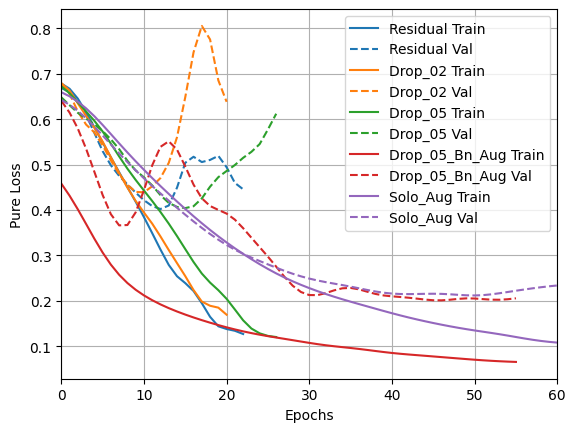

In [ ]:
!pip install git+https://github.com/tensorflow/docs
import tensorflow_docs as tfdocs
import tensorflow_docs.modeling
import tensorflow_docs.plots

histories = {}
histories['residual'] = histories_residual
histories['drop_02'] = histories_residual_drop_02
histories['drop_05'] = histories_residual_drop_05
histories['drop_05_bn_aug'] = histories_residual_drop_05_bn_aug
histories['solo_aug'] = histories_residual_solo_aug

plotter = tfdocs.plots.HistoryPlotter(metric = 'pure_loss', smoothing_std=10)
plotter.plot(histories)